# 17. Road Crash Seasonality

Which observed periods have unusually high crash counts?

Primary source: https://microdata.nigerianstat.gov.ng/index.php/catalog/164

Quarterly totals do not reveal dangerous hours or weekdays. Event timestamps are required for finer timing.

This notebook runs the implemented aggregate-indicator workflow. National preview outputs do not complete the primary case study.

In [1]:
from pathlib import Path
import sys
project=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
sys.path.insert(0,str(project.parents[1]))
from src.pipeline import run
status=run(project)
status

Out[0]: 
{'status': 'EXECUTED',
 'scope': 'PRIMARY_NBS_TABLES',
 'utc': '2026-11-21T18:10:36.649675+00:00',
 'rows': 22,
 'metrics': ['Total crashes'],
 'primary_case_complete': True,
 'native_bi_validated': False,
 'primary_analysis_executed': True,
 'remaining_limit': 'Only quarterly timing is observed. The balanced seasonality comparison uses 2021–2025, five complete years. No hour-of-day risk or prospective safety advice is inferred.'}


,period,geography,metric,value,unit,source_url,vintage,previous_value,previous_period,absolute_change,relative_change_pct
0,2020-10-01,Nigeria,Total crashes,3313.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,NaN,NaN,NaN,NaN
1,2021-01-01,Nigeria,Total crashes,3301.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3313.0,2020-10-01,-12.0,-0.362209
2,2021-04-01,Nigeria,Total crashes,3185.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3301.0,2021-01-01,-116.0,-3.514087
3,2021-07-01,Nigeria,Total crashes,3134.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3185.0,2021-04-01,-51.0,-1.601256
4,2021-10-01,Nigeria,Total crashes,3407.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3134.0,2021-07-01,273.0,8.710913
5,2022-01-01,Nigeria,Total crashes,3345.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3407.0,2021-10-01,-62.0,-1.819783
6,2022-04-01,Nigeria,Total crashes,3282.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3345.0,2022-01-01,-63.0,-1.883408
7,2022-07-01,Nigeria,Total crashes,3412.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3282.0,2022-04-01,130.0,3.960999
8,2022-10-01,Nigeria,Total crashes,3617.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3412.0,2022-07-01,205.0,6.008206
9,2023-01-01,Nigeria,Total crashes,2733.0,crashes,https://microdata.nigerianstat.gov.ng/index.ph...,NBS Q1 2026 release,3617.0,2022-10-01,-884.0,-24.440144


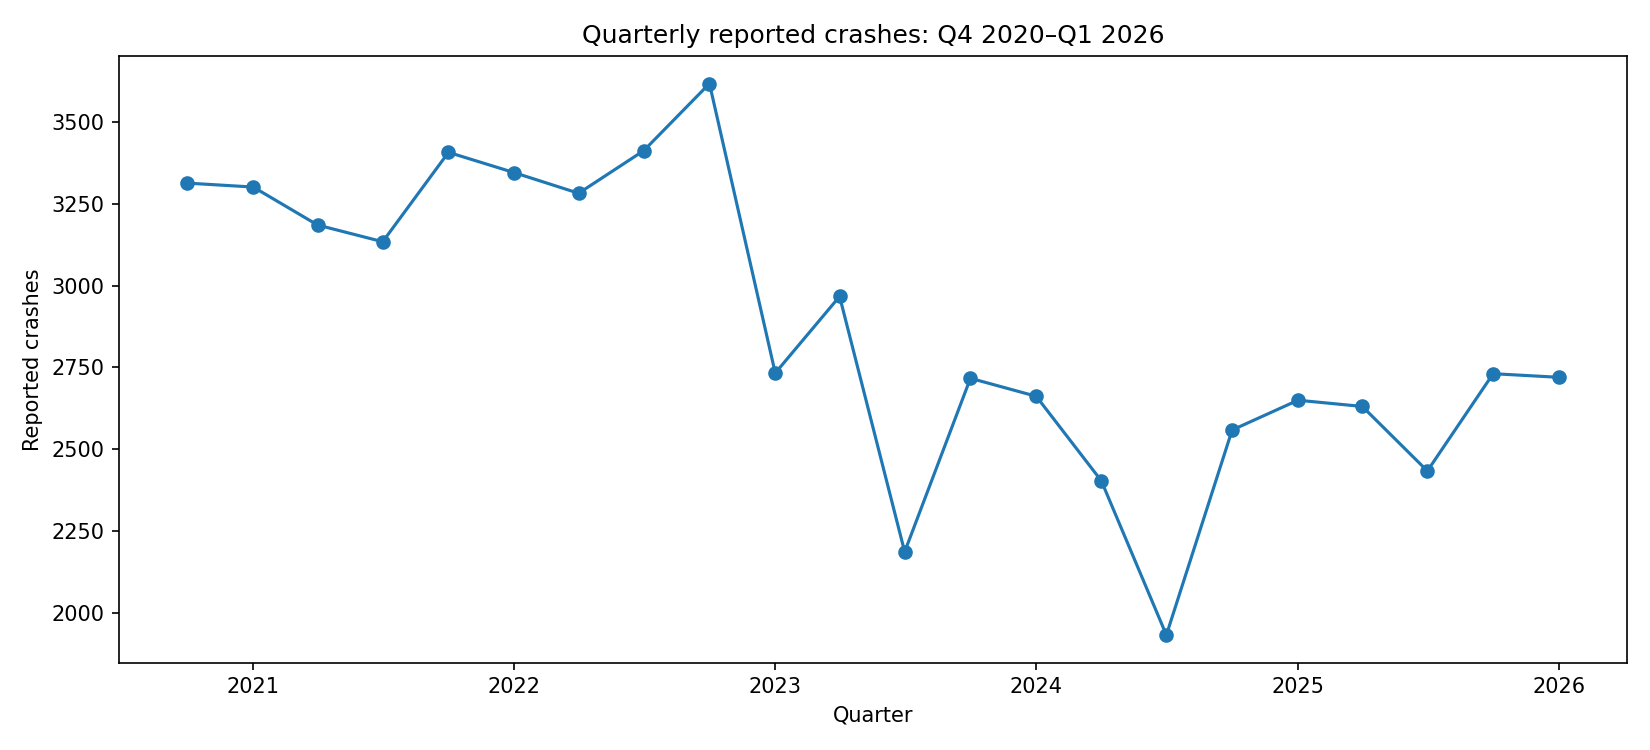

In [2]:
import pandas as pd
from IPython.display import display, Image
if status['status']=='EXECUTED':
    display(pd.read_csv(project/'outputs/analysis.csv').head(25))
    display(Image(filename=str(project/'outputs/trend.png')))
else:
    print(status['reason'])

In [3]:
display(pd.read_csv(project/'outputs/primary_analysis.csv').head(20))
print((project/'reports/RESULTS.md').read_text())

# Road Crash Seasonality: primary NBS analysis

Q1 2026 recorded 2,720 crashes, a +2.64% change from Q1 2025.

## Evidence and validation
22 quarters × 37 states/FCT = 814 state-quarter records. All eight state-count columns reconcile to source national totals in every quarter. Severity categories and casualty components reconcile for every state-quarter. The latest-quarter factor columns separately reconcile to published national totals. The adapter records source hashes and exact workbook rows.

## Methods
SQL is in sql/primary_analysis.sql. Source: https://microdata.nigerianstat.gov.ng/index.php/catalog/164/download/1405. Data tables and a balanced-period seasonality comparison are exported in outputs/.

![Primary chart](../outputs/trend.png)

## Limits
Only quarterly timing is observed. The balanced seasonality comparison uses 2021–2025, five complete years. No hour-of-day risk or prospective safety advice is inferred.

## Decision use
Use counts to select locations or periods for 

,period,year,quarter,crashes,deaths,same_quarter_previous_year,yoy_change_pct
0,2020-10-01,2020,4,3313.0,1818.0,NaN,NaN
1,2021-01-01,2021,1,3301.0,1668.0,NaN,NaN
2,2021-04-01,2021,2,3185.0,1453.0,NaN,NaN
3,2021-07-01,2021,3,3134.0,1432.0,NaN,NaN
4,2021-10-01,2021,4,3407.0,1652.0,3313.0,2.837308
5,2022-01-01,2022,1,3345.0,1834.0,3301.0,1.332929
6,2022-04-01,2022,2,3282.0,1538.0,3185.0,3.045526
7,2022-07-01,2022,3,3412.0,1476.0,3134.0,8.870453
8,2022-10-01,2022,4,3617.0,1608.0,3407.0,6.163780
9,2023-01-01,2023,1,2733.0,1441.0,3345.0,-18.295964


## Interpretation
Review changes within each metric and unit separately. Changes span previous available observations, not necessarily one year. Percentage-point changes and relative percentage changes are different. No causal inference is made. Survey-design uncertainty is not estimated by this aggregate pipeline.